In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

In [4]:
import pandas as pd
file_path1 = "Bird_Monitoring_Data_FOREST.XLSX"
file_path2 = "Bird_Monitoring_Data_GRASSLAND.XLSX"

excel_data1 = pd.ExcelFile(file_path1)
excel_data2 = pd.ExcelFile(file_path2)

sheet_names1 = excel_data1.sheet_names
sheet_names2 = excel_data1.sheet_names

sheets_dict1 = {sheet: excel_data1.parse(sheet) for sheet in sheet_names1}
sheets_dict2 = {sheet: excel_data2.parse(sheet) for sheet in sheet_names2}


In [7]:

combined_df1 = pd.concat(
    [df.assign(Sheet=sheet_name) for sheet_name, df in sheets_dict1.items()],
    ignore_index=True
)

combined_df2 = pd.concat(
    [df.assign(Sheet=sheet_name) for sheet_name, df in sheets_dict2.items()],
    ignore_index=True
)

/tmp/ipython-input-659286742.py:6: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  combined_df2 = pd.concat(


In [8]:
combined_df1 = combined_df1.drop(columns=['Sheet'])
combined_df2 = combined_df2.drop(columns=['Sheet'])

In [30]:
combined_df = pd.concat([combined_df1, combined_df2], ignore_index=True)

In [31]:
combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17077 entries, 0 to 17076
Data columns (total 32 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   Admin_Unit_Code              17077 non-null  object        
 1   Sub_Unit_Code                722 non-null    object        
 2   Site_Name                    8546 non-null   object        
 3   Plot_Name                    17077 non-null  object        
 4   Location_Type                17077 non-null  object        
 5   Year                         17077 non-null  object        
 6   Date                         17077 non-null  datetime64[ns]
 7   Start_Time                   17077 non-null  object        
 8   End_Time                     17077 non-null  object        
 9   Observer                     17077 non-null  object        
 10  Visit                        17077 non-null  object        
 11  Interval_Length              17077 non-nu

In [32]:
null_summary = combined_df.isnull().sum()
print("Null values in each column:\n", null_summary)

Null values in each column:
 Admin_Unit_Code                    0
Sub_Unit_Code                  16355
Site_Name                       8531
Plot_Name                          0
Location_Type                      0
Year                               0
Date                               0
Start_Time                         0
End_Time                           0
Observer                           0
Visit                              0
Interval_Length                    0
ID_Method                          2
Distance                        1486
Flyover_Observed                   0
Sex                             5183
Common_Name                        0
Scientific_Name                    0
AcceptedTSN                       33
NPSTaxonCode                    8531
AOU_Code                           0
PIF_Watchlist_Status               0
Regional_Stewardship_Status        0
Temperature                        0
Humidity                           0
Sky                                0
Wind     

In [36]:

combined_df.fillna(method='ffill', inplace=True)


/tmp/ipython-input-456119625.py:1: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  combined_df.fillna(method='ffill', inplace=True)
/tmp/ipython-input-456119625.py:1: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  combined_df.fillna(method='ffill', inplace=True)


In [38]:
combined_df.shape


(17077, 32)

In [37]:
combined_df.isna().sum()

,0
Admin_Unit_Code,0
Sub_Unit_Code,3378
Site_Name,0
Plot_Name,0
Location_Type,0
Year,0
Date,0
Start_Time,0
End_Time,0
Observer,0


In [48]:
combined_df

,Admin_Unit_Code,Site_Name,Plot_Name,Location_Type,Year,Date,Start_Time,End_Time,Observer,Visit,...,AOU_Code,PIF_Watchlist_Status,Regional_Stewardship_Status,Temperature,Humidity,Sky,Wind,Disturbance,Initial_Three_Min_Cnt,Habitat
0,ANTI,ANTI 1,ANTI-0036,Forest,2018,2018-05-22,06:19:00,06:29:00,Elizabeth Oswald,1,...,EATO,False,True,19.9,79.400002,Cloudy/Overcast,Calm (< 1 mph) smoke rises vertically,No effect on count,True,Forest
1,ANTI,ANTI 1,ANTI-0036,Forest,2018,2018-05-22,06:19:00,06:29:00,Elizabeth Oswald,1,...,WBNU,False,False,19.9,79.400002,Cloudy/Overcast,Calm (< 1 mph) smoke rises vertically,No effect on count,True,Forest
2,ANTI,ANTI 1,ANTI-0036,Forest,2018,2018-05-22,06:19:00,06:29:00,Elizabeth Oswald,1,...,RBWO,False,False,19.9,79.400002,Cloudy/Overcast,Calm (< 1 mph) smoke rises vertically,No effect on count,False,Forest
3,ANTI,ANTI 1,ANTI-0036,Forest,2018,2018-05-22,06:19:00,06:29:00,Elizabeth Oswald,1,...,OROR,False,False,19.9,79.400002,Cloudy/Overcast,Calm (< 1 mph) smoke rises vertically,No effect on count,False,Forest
4,ANTI,ANTI 1,ANTI-0036,Forest,2018,2018-05-22,06:19:00,06:29:00,Elizabeth Oswald,1,...,NOMO,False,False,19.9,79.400002,Cloudy/Overcast,Calm (< 1 mph) smoke rises vertically,No effect on count,False,Forest
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17072,MONO,WOTR,MONO-0089,Grassland,2018,2018-05-10,06:35:00,06:46:00,Brian Swimelar,1,...,EUST,False,False,19.0,63.000000,Partly Cloudy,Light air movement (1-3 mph) smoke drifts,Slight effect on count,False,Grassland
17073,MONO,WOTR,MONO-0089,Grassland,2018,2018-05-10,06:35:00,06:46:00,Brian Swimelar,1,...,EUST,False,False,19.0,63.000000,Partly Cloudy,Light air movement (1-3 mph) smoke drifts,Slight effect on count,False,Grassland
17074,MONO,WOTR,MONO-0089,Grassland,2018,2018-05-10,06:35:00,06:46:00,Brian Swimelar,1,...,EUST,False,False,19.0,63.000000,Partly Cloudy,Light air movement (1-3 mph) smoke drifts,Slight effect on count,False,Grassland
17075,MONO,WOTR,MONO-0089,Grassland,2018,2018-05-10,06:35:00,06:46:00,Brian Swimelar,1,...,EUST,False,False,19.0,63.000000,Partly Cloudy,Light air movement (1-3 mph) smoke drifts,Slight effect on count,False,Grassland


In [40]:
combined_df.drop(['TaxonCode','Previously_Obs','Sub_Unit_Code'], inplace=True, axis=1)

In [42]:
combined_df.isna().sum()

,0
Admin_Unit_Code,0
Site_Name,0
Plot_Name,0
Location_Type,0
Year,0
Date,0
Start_Time,0
End_Time,0
Observer,0
Visit,0


In [43]:
combined_df.columns

Index(['Admin_Unit_Code', 'Site_Name', 'Plot_Name', 'Location_Type', 'Year',
       'Date', 'Start_Time', 'End_Time', 'Observer', 'Visit',
       'Interval_Length', 'ID_Method', 'Distance', 'Flyover_Observed', 'Sex',
       'Common_Name', 'Scientific_Name', 'AcceptedTSN', 'NPSTaxonCode',
       'AOU_Code', 'PIF_Watchlist_Status', 'Regional_Stewardship_Status',
       'Temperature', 'Humidity', 'Sky', 'Wind', 'Disturbance',
       'Initial_Three_Min_Cnt', 'Habitat'],
      dtype='object')

In [47]:
fig = px.histogram(combined_df, x='Initial_Three_Min_Cnt', nbins=30, marginal='box',
                   title='Distribution of Initial_Three_Min_Cnt (Plotly)')
fig.show()

In [50]:
if combined_df['Date'].notna().any():
    combined_df['Month'] = combined_df['Date'].dt.month
    monthly = combined_df.groupby('Month')['Initial_Three_Min_Cnt'].sum().reset_index()
    fig = px.bar(monthly, x='Month', y='Initial_Three_Min_Cnt', title='Monthly Total Counts (Plotly)')
    fig.show()

/tmp/ipython-input-624078376.py:3: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




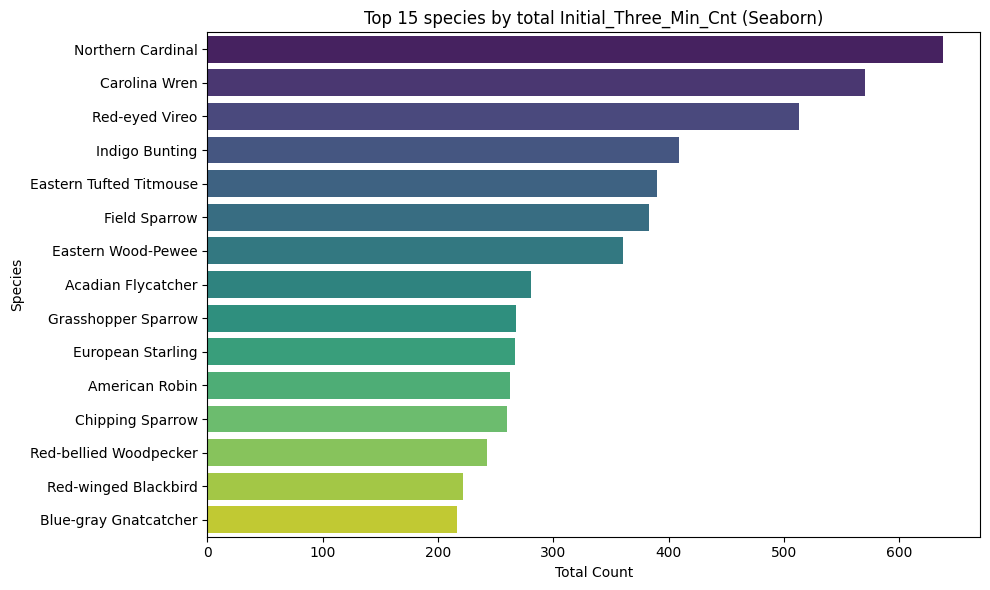

In [51]:
top_species = combined_df.groupby('Common_Name')['Initial_Three_Min_Cnt'].sum().sort_values(ascending=False).head(15)
plt.figure(figsize=(10,6))
sns.barplot(x=top_species.values, y=top_species.index, palette='viridis')
plt.title('Top 15 species by total Initial_Three_Min_Cnt (Seaborn)')
plt.xlabel('Total Count')
plt.ylabel('Species')
plt.tight_layout()
plt.show()

In [53]:
if 'Plot_Name' in combined_df.columns:
    treemap_df = combined_df.groupby(['Site_Name','Plot_Name'])['Initial_Three_Min_Cnt'].sum().reset_index()
    fig = px.treemap(treemap_df, path=['Site_Name','Plot_Name'], values='Initial_Three_Min_Cnt',
                     title='Treemap: Counts by Site and Plot')
    fig.show()

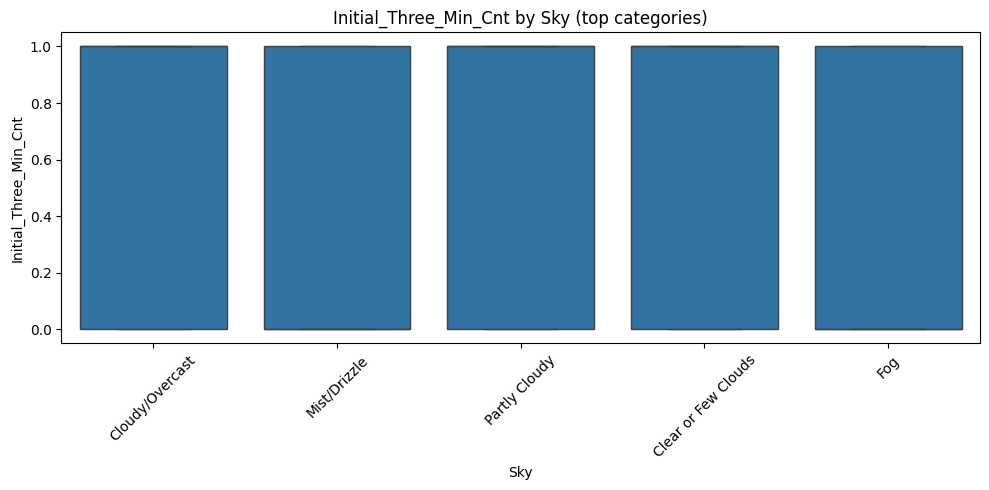

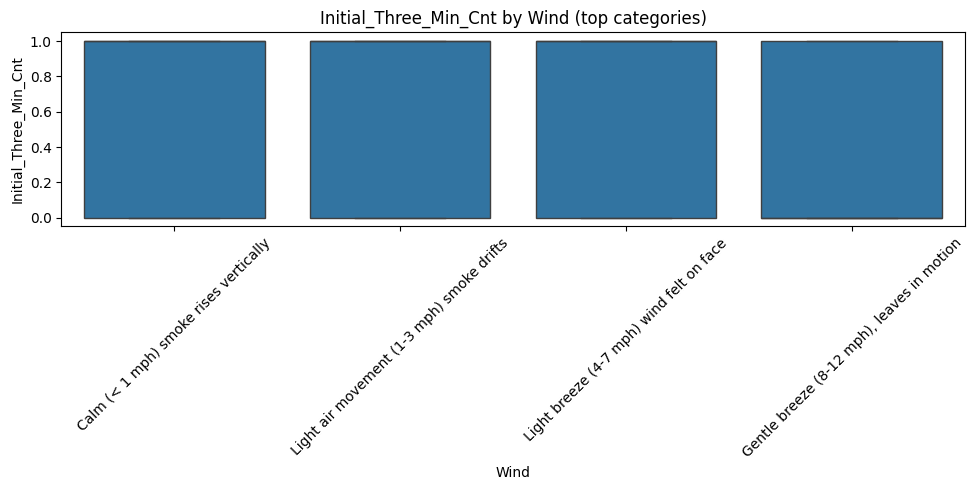

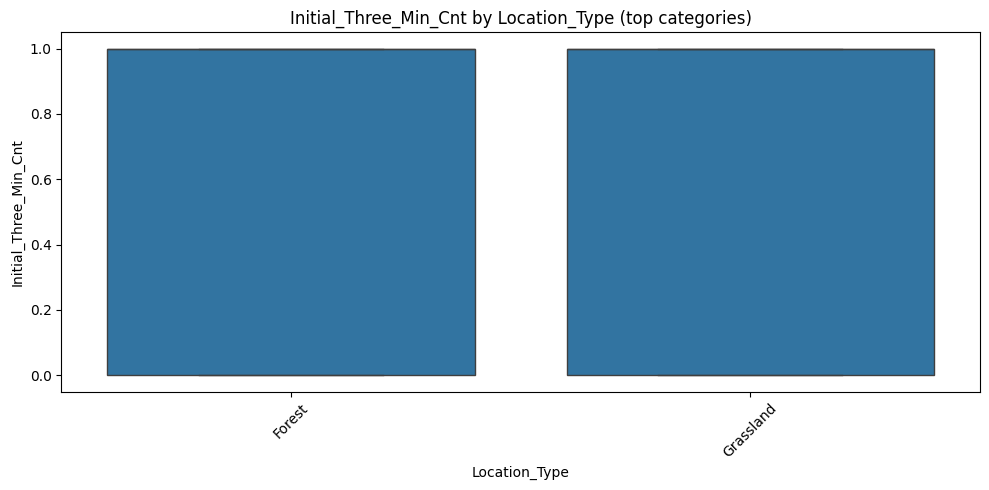

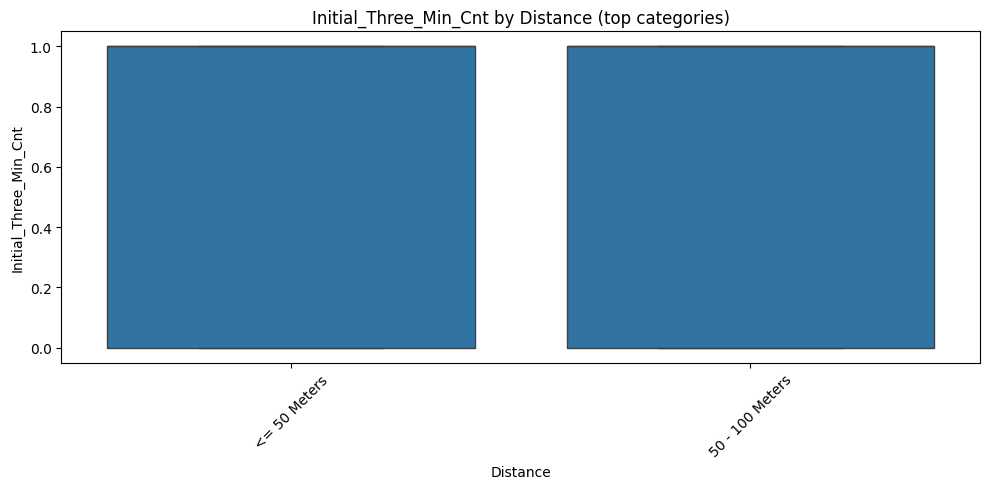

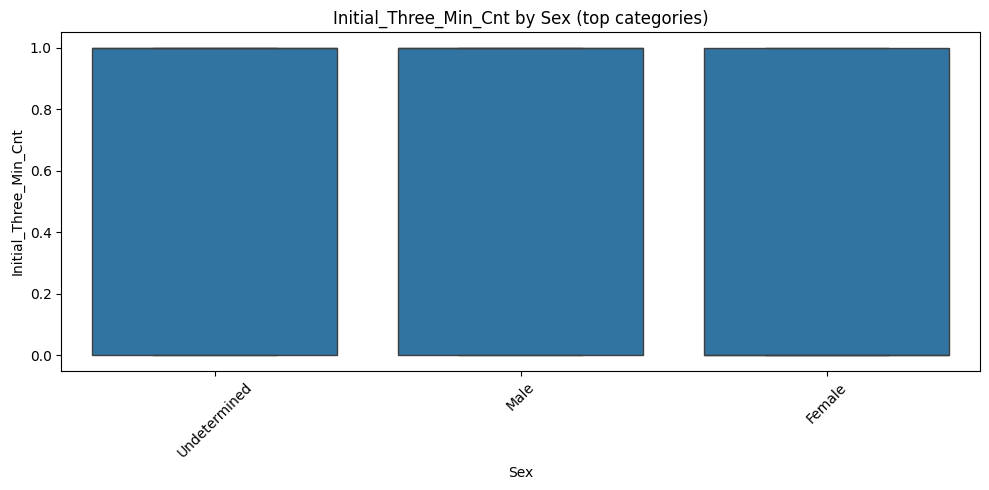

In [56]:
for col in ['Sky','Wind','Location_Type','Distance','Sex']:
    if col in combined_df.columns:
        top_levels = combined_df[col].value_counts().nlargest(12).index
        plt.figure(figsize=(10,5))
        sns.boxplot(data=combined_df[combined_df[col].isin(top_levels)], x=col, y='Initial_Three_Min_Cnt')
        plt.xticks(rotation=45)
        plt.title(f'Initial_Three_Min_Cnt by {col} (top categories)')
        plt.tight_layout()
        plt.show()


Top observers by total counts:
            Observer  count   sum      mean
1  Elizabeth Oswald   6391  3642  0.569864
2    Kimberly Serno   5902  3225  0.546425
0    Brian Swimelar   4784  2275  0.475543


/tmp/ipython-input-3439224972.py:6: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.




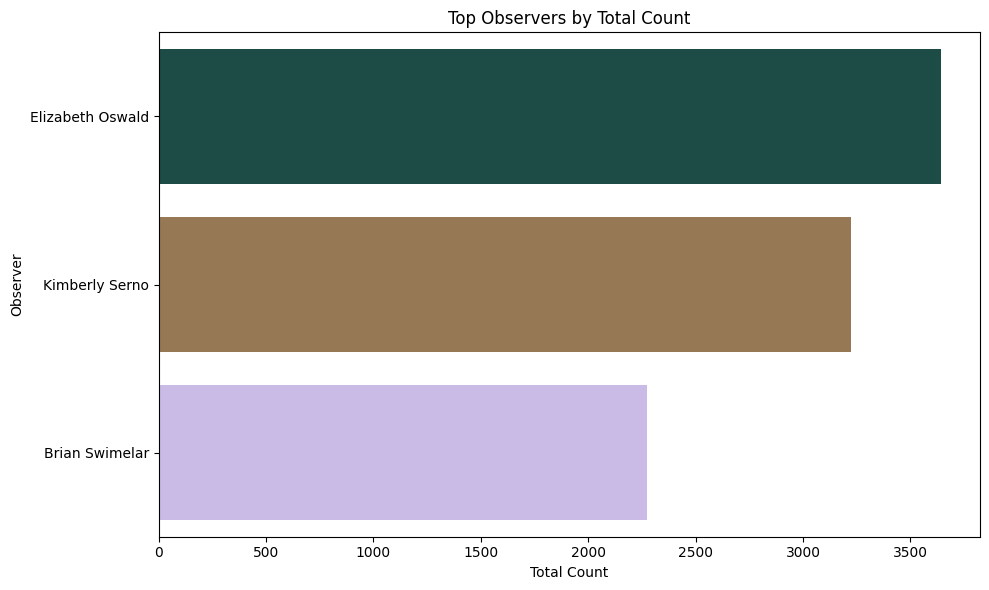

In [58]:
obs_summary = combined_df.groupby('Observer')['Initial_Three_Min_Cnt'].agg(['count','sum','mean']).reset_index().sort_values('sum', ascending=False)
print("\nTop observers by total counts:\n", obs_summary.head(10))

top_obs = obs_summary.head(15)
plt.figure(figsize=(10,6))
sns.barplot(x='sum', y='Observer', data=top_obs, palette='cubehelix')
plt.xlabel('Total Count'); plt.title('Top Observers by Total Count')
plt.tight_layout()
plt.show()


In [60]:
if 'Habitat' in combined_df.columns:
    # Group and get top species per habitat
    top_species_hab = (
        combined_df
        .groupby(['Habitat', 'Common_Name'])['Initial_Three_Min_Cnt']
        .sum()
        .reset_index()
    )

    top_by_habitat = (
        top_species_hab
        .sort_values(['Habitat', 'Initial_Three_Min_Cnt'], ascending=[True, False])
        .groupby('Habitat')
        .head(10)
    )

    print("\nTop species by habitat (top 10 each):")
    print(top_by_habitat)

    # Plotly bar chart
    fig = px.bar(
        top_by_habitat,
        x="Common_Name",
        y="Initial_Three_Min_Cnt",
        color="Habitat",
        facet_col="Habitat",
        facet_col_wrap=3,  # Adjust columns per row
        text="Initial_Three_Min_Cnt",
        title="Top 10 Species by Habitat",
        height=800
    )

    fig.update_traces(textposition='outside')
    fig.update_xaxes(tickangle=45, title="")
    fig.update_yaxes(title="Count (Initial Three Min)")

    fig.show()


Top species by habitat (top 10 each):
       Habitat              Common_Name  Initial_Three_Min_Cnt
77      Forest           Red-eyed Vireo                    486
24      Forest            Carolina Wren                    360
63      Forest        Northern Cardinal                    320
40      Forest       Eastern Wood-Pewee                    314
39      Forest  Eastern Tufted Titmouse                    296
0       Forest       Acadian Flycatcher                    266
76      Forest   Red-bellied Woodpecker                    205
71      Forest                 Ovenbird                    192
100     Forest              Wood Thrush                    192
17      Forest    Blue-gray Gnatcatcher                    168
151  Grassland            Field Sparrow                    364
162  Grassland           Indigo Bunting                    322
168  Grassland        Northern Cardinal                    318
150  Grassland        European Starling                    265
153  Grassland  

In [61]:
combined_df.to_csv('birds_observed_cleaned data.csv', index=False)